# Correlation and what it misses

Correlation is the first number to look at when asking which features are related to the target, and to each other. It is quick and useful, as long as it is read for what it measures: how closely the points of a scatter plot follow a straight line. Read as anything more (how strongly one variable depends on the other, or whether one causes the other) it misleads.

## Pearson's coefficient, by hand

The age and price of six used cars:

In [ ]:
import pandas as pd

cars = pd.DataFrame({
    "age_years": [3, 10, 6, 1, 8, 5],
    "price": [14_500, 4_200, 9_800, 21_000, 6_100, 11_200],
})
cars

,age_years,price
0,3,14500
1,10,4200
2,6,9800
3,1,21000
4,8,6100
5,5,11200


**Pearson's correlation coefficient**, usually just "the correlation", standardises both columns (subtracts the mean and divides by the standard deviation, so that each is measured in standard deviations from its mean), multiplies them row by row, and averages the products:

$$r = \frac{1}{n-1}\sum_{i=1}^{n} \frac{x_i - \bar{x}}{s_x}\cdot\frac{y_i - \bar{y}}{s_y}$$

A product is positive when the car is on the same side of both means (older than average and cheaper than average gives a negative product; older and dearer, a positive one), so the average says whether the two columns tend to move together or in opposite directions. Step by step:

In [ ]:
standardised = (cars - cars.mean()) / cars.std()
standardised.assign(product=standardised["age_years"] * standardised["price"]).round(2)

,age_years,price,product
0,-0.76,0.56,-0.42
1,1.38,-1.14,-1.57
2,0.15,-0.22,-0.03
3,-1.38,1.63,-2.24
4,0.76,-0.83,-0.63
5,-0.15,0.01,-0.00


In [ ]:
products = standardised["age_years"] * standardised["price"]
(products.sum() / (len(cars) - 1)).round(3)

np.float64(-0.981)

Every product is negative: in each car, being older than average goes with being cheaper than average. pandas computes the same number for every pair of columns at once:

In [ ]:
cars.corr()

,age_years,price
age_years,1.000000,-0.981017
price,-0.981017,1.000000


The coefficient is always between −1 and 1:

- **1** or **−1**: the points lie exactly on a straight line, rising or falling.
- **0**: no straight line fits them better than a horizontal one.
- In between, the closer to 1 or −1, the more tightly the points follow a line. Here, −0.98: as age rises, price falls, almost along a line.

Standardising first makes the coefficient independent of units: prices in euros or in thousands of euros give the same value.

## A correlation matrix

The penguins of [Exploring a dataset](exploring_a_dataset.ipynb), with a different question: how heavy a penguin is, from its other measurements. Since the correlations will guide choices about the model, they are computed on the training rows only, split as in that notebook:

In [ ]:
import seaborn as sns
from sklearn.model_selection import train_test_split

penguins = sns.load_dataset("penguins", data_home="data")
measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins = penguins.dropna(subset=measurements, how="all")
train, test = train_test_split(penguins, test_size=0.2, stratify=penguins["species"], random_state=42)
correlations = train[measurements].corr()
correlations.round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.23,0.66,0.60
bill_depth_mm,-0.23,1.00,-0.59,-0.48
flipper_length_mm,0.66,-0.59,1.00,0.87
body_mass_g,0.60,-0.48,0.87,1.00


The matrix is symmetric (the correlation of A with B is that of B with A), and its diagonal is 1 (every column is perfectly correlated with itself). The column of the target, sorted by strength whatever the sign, since a strong negative correlation is as informative as a strong positive one:

In [ ]:
import numpy as np

correlations["body_mass_g"].drop("body_mass_g").sort_values(key=np.abs, ascending=False).round(2)

flipper_length_mm    0.87
bill_length_mm       0.60
bill_depth_mm       -0.48
Name: body_mass_g, dtype: float64

Flipper length goes with body mass most closely (0.87), then bill length (0.60), and bill depth goes against it (−0.48): penguins with deeper bills would seem to be lighter. That last reading is misleading: it holds for the mix of species, not inside any of them, as the rest of this notebook shows, and a scatter plot is the first step to seeing why.

## Only straight lines

A coefficient near 0 doesn't mean that two variables are unrelated. Here $y$ is completely determined by $x$:

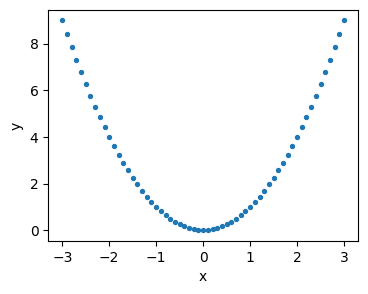

In [ ]:
parabola = pd.DataFrame({"x": np.linspace(-3, 3, 61)}).assign(y=lambda frame: frame["x"] ** 2)
parabola.plot.scatter(x="x", y="y", s=8, figsize=(4, 3));

In [ ]:
abs(parabola["x"].corr(parabola["y"])).round(3)

np.float64(0.0)

The correlation is 0 (a tiny floating-point error, whose sign means nothing, hidden by `abs`): on the left $y$ falls as $x$ grows, on the right it rises, and the two halves cancel out. No straight line fits better than a horizontal one, although the relationship is perfect.

The opposite trap is a high coefficient over very different shapes. Statistician Francis Anscombe built four small datasets in 1973 to make the point; here they are, typed in:

In [ ]:
anscombe_x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = {
    "I": (anscombe_x, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II": (anscombe_x, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (anscombe_x, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV": ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
pd.DataFrame({
    name: {"mean of y": np.mean(y), "variance of y": np.var(y, ddof=1), "correlation": np.corrcoef(x, y)[0, 1]}
    for name, (x, y) in anscombe.items()
}).round(2)

,I,II,III,IV
mean of y,7.50,7.50,7.50,7.50
variance of y,4.13,4.13,4.12,4.12
correlation,0.82,0.82,0.82,0.82


The same means, almost the same variances, and the same correlation, 0.82. Drawn:

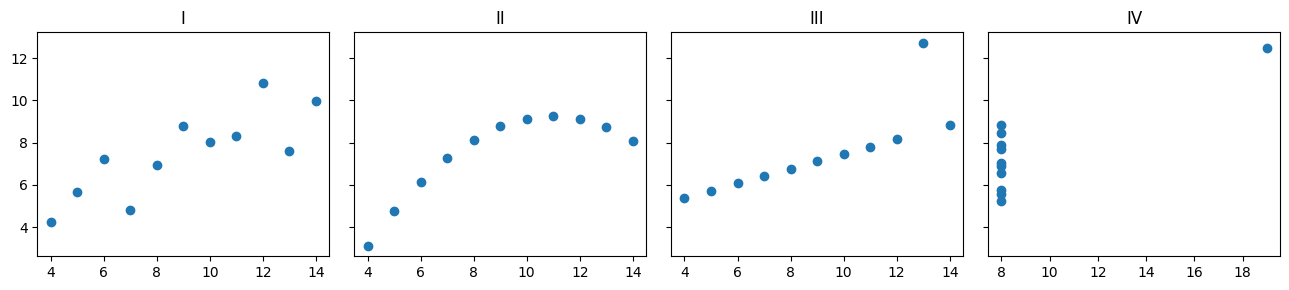

In [ ]:
import matplotlib.pyplot as plt
figure, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for axis, (name, (x, y)) in zip(axes, anscombe.items()):
    axis.scatter(x, y)
    axis.set_title(name)
figure.tight_layout()

- **I** is what a correlation of 0.82 suggests: a cloud around a rising line.
- **II** is a perfect curve, not a line.
- **III** is a perfect line spoiled by one point, which lowers the coefficient from 1 to 0.82.
- **IV** has no relationship at all: $x$ is 8 for ten points, and one point at 19 creates the whole correlation.

One number can't tell these apart; the plot can. And a single extreme point can make or break a correlation ([Outliers and capped values](outliers.ipynb)).

## Spearman's coefficient

**Spearman's coefficient** is Pearson's computed on the ranks of the values instead of the values themselves (1 for the smallest, 2 for the next…). It measures whether $y$ grows whenever $x$ grows, along any curve, not only a straight line. An exponential is a monotonic relationship (always rising) that is far from a line:

In [ ]:
exponential = pd.DataFrame({"x": np.linspace(0, 5, 51)}).assign(y=lambda frame: np.exp(frame["x"]))
pd.Series({
    "Pearson": exponential.corr(method="pearson").loc["x", "y"],
    "Spearman": exponential.corr(method="spearman").loc["x", "y"],
}).round(3)

Pearson     0.854
Spearman    1.000
dtype: float64

Spearman's coefficient is 1: the ranks of $x$ and $y$ are identical. Pearson's, 0.85, says only that a line fits imperfectly. Because it uses ranks, Spearman's coefficient is also less sensitive to a single extreme value, whose rank can't be more extreme than first or last, however far the value is:

In [ ]:
pd.DataFrame({
    name: {
        "Pearson": pd.Series(x).corr(pd.Series(y)),
        "Spearman": pd.Series(x).corr(pd.Series(y), method="spearman"),
    }
    for name, (x, y) in anscombe.items()
}).round(2)

,I,II,III,IV
Pearson,0.82,0.82,0.82,0.82
Spearman,0.82,0.69,0.99,0.50


On dataset III, the line spoiled by one point, Spearman gives 0.99, close to the perfect relationship of the other ten points. Neither coefficient sees through dataset II's curve, which rises and then falls.

## A correlation that reverses inside each group

Back to the penguins: bill depth correlates negatively with body mass. Drawn with each species in its own colour:

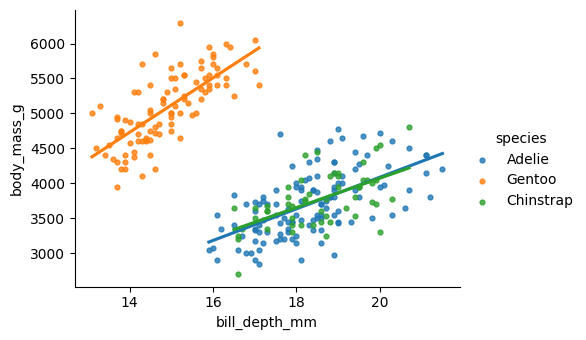

In [ ]:
sns.lmplot(train, x="bill_depth_mm", y="body_mass_g", hue="species", height=3.5, aspect=1.4, ci=None,
           scatter_kws={"s": 12});

Inside every species, the line rises: penguins with deeper bills are heavier. The correlation within each species, against the one over all of them:

In [ ]:
within_species = train.groupby("species")[["bill_depth_mm", "body_mass_g"]].corr().xs("bill_depth_mm", level=1)["body_mass_g"]
pd.concat([within_species, pd.Series({"all species together": train["bill_depth_mm"].corr(train["body_mass_g"])})]).round(2)

Adelie                  0.59
Chinstrap               0.58
Gentoo                  0.72
all species together   -0.48
dtype: float64

Between 0.58 and 0.72 inside each species, −0.48 over all of them. The species explain it: Gentoo penguins are the heaviest and have the shallowest bills, so mixing them with the others creates a falling trend *between* the species that hides the rising trend *within* each one. A relationship that reverses when the data are split into groups is called **Simpson's paradox**. Bill length against bill depth, seen in [Exploring a dataset](exploring_a_dataset.ipynb), is another case:

In [ ]:
within_species = train.groupby("species")[["bill_length_mm", "bill_depth_mm"]].corr().xs("bill_length_mm", level=1)["bill_depth_mm"]
pd.concat([within_species, pd.Series({"all species together": train["bill_length_mm"].corr(train["bill_depth_mm"])})]).round(2)

Adelie                  0.38
Chinstrap               0.62
Gentoo                  0.69
all species together   -0.23
dtype: float64

When the rows come from groups that differ (species, regions, kinds of customer), a correlation over all of them may describe the mix of groups rather than any relationship inside them. A model that sees the group as a feature can learn both.

## Correlation is not causation

A correlation says that two columns move together in this data, not that one causes the other, nor that changing one would change the other. Flipper length and body mass correlate at 0.87 because both grow with the size of the bird; lengthening a flipper wouldn't make a penguin heavier. Two columns may also correlate because the cause runs the other way, or only by chance, in a small sample.

For prediction, a correlation without causation can still be useful: a feature that only goes with the target can help predict it, as long as the reason it goes with it still holds where the model is used. That is the question about the islands in [Exploring a dataset](exploring_a_dataset.ipynb).

## What correlations are used for

- **A first list of candidate features**, not a selection. A feature with a correlation near 0 may still matter: through a curve (the parabola), together with another feature, or inside groups. Models such as trees use those relationships without any help; for a linear model they may need [new features](creating_features.ipynb).
- **Spotting features that carry the same information.** Two features with a correlation near 1 or −1 are partly redundant. It rarely hurts a model's predictions, but it makes the weights of a linear model unstable and hard to read ([Regularisation](../../supervised-learning/ml-fundamentals/regularization.ipynb)).
- **Checking a new feature** against the target, such as a ratio of two columns ([Creating features](creating_features.ipynb)).

Pearson's and Spearman's coefficients need numbers. For a categorical feature, compare the target across the categories, as with the islands and the species in [Exploring a dataset](exploring_a_dataset.ipynb).